# 01 · EDA: что в данных М.Видео и что из этого можно извлечь

**Вопросы ноутбука:**
1. Что лежит в выдаче, как файлы связаны и какой набор можно считать размеченным.
2. Какие характеристики есть в каталоге и какую их часть вообще можно найти в тексте карточки.
3. Где сосредоточен трафик покупателей, то есть что важнее заполнять в первую очередь.
4. Какие утечки возможны при оценке и как разбивать данные.

Контракт данных и метрик, который следует из анализа: [`docs/DATA_CONTRACT.md`](../docs/DATA_CONTRACT.md).

Путь к данным задаётся переменной окружения `ATTRX_DATA_DIR`. В ней лежат `cu_ws/` (выдача) и `processed/` (результат `scripts/convert_skus.py`).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

from attrx.catalog import DataPaths, build, load, SERVICE_ATTRIBUTES
from attrx import metrics as M

candidates = [os.environ.get("ATTRX_DATA_DIR"), "../data/real", str(Path.home() / "hackathon_data")]
DATA_DIR = next(Path(p) for p in candidates if p and (Path(p) / "cu_ws").exists())
P = DataPaths(DATA_DIR)
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
pl.Config.set_tbl_rows(25); pl.Config.set_fmt_str_lengths(60); pl.Config.set_tbl_width_chars(160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("DATA_DIR:", DATA_DIR)

DATA_DIR: C:\Users\ibrag\hackathon_data


## 1. Состав выдачи

| Файл | Что внутри |
|---|---|
| `sku_desc.parquet` | текст карточек: `sku_id`, `title`, `description` |
| `query_clicks.parquet` | клики из поиска: запрос → товар, бренд, цена, категория (`sku_seo_id`) |
| `skus.pkl` | YML-каталог: товары (`vendor`, `model`, `categoryId`), характеристики `param`, дерево категорий |

`skus.pkl` не загружаем через `pickle.load`: это небезопасно и требует больше 6 ГБ памяти. Файл потоково конвертирует `scripts/convert_skus.py` собственным интерпретатором ограниченного набора инструкций.

In [2]:
desc = pl.scan_parquet(P.raw / "sku_desc.parquet")
d = desc.select(
    pl.len().alias("карточек"),
    pl.col("sku_id").n_unique().alias("уникальных sku"),
    (pl.col("description").is_null() | (pl.col("description").str.len_chars() == 0)).mean().alias("доля пустых описаний"),
    pl.col("description").str.len_chars().median().alias("медиана длины описания"),
    pl.col("description").str.contains("<br|<p>|<li").mean().alias("доля HTML"),
    pl.col("description").str.contains("•").mean().alias("доля буллетов"),
    pl.col("title").str.ends_with(" -").mean().alias("доля названий с « -» в конце"),
).collect()
qc = pl.scan_parquet(P.raw / "query_clicks.parquet")
q = qc.select(pl.len().alias("кликов"), pl.col("sku_id").n_unique().alias("sku с кликами"),
              pl.col("toValidUTF8(query_text)").n_unique().alias("уникальных запросов")).collect()
offers = pl.scan_parquet(P.processed / "offers" / "*.parquet")
params = pl.scan_parquet(P.processed / "params" / "*.parquet")
o = offers.select(pl.len().alias("товаров в каталоге"), pl.col("category_id").n_unique().alias("категорий")).collect()
pr = params.select(pl.len().alias("строк param"), pl.col("name").str.ends_with("_search").sum().alias("из них _search")).collect()
for k, v in d.row(0, named=True).items():
    print(f"{k:32} {v:,.0f}" if v >= 10 else f"{k:32} {v:.1%}")
print(q); print(o); print(pr)

карточек                         1,177,200
уникальных sku                   1,177,200
доля пустых описаний             0.0%
медиана длины описания           630
доля HTML                        49.3%
доля буллетов                    32.4%
доля названий с « -» в конце     26.1%
shape: (1, 3)
┌──────────┬───────────────┬─────────────────────┐
│ кликов   ┆ sku с кликами ┆ уникальных запросов │
│ ---      ┆ ---           ┆ ---                 │
│ u32      ┆ u32           ┆ u32                 │
╞══════════╪═══════════════╪═════════════════════╡
│ 30991350 ┆ 332753        ┆ 1789579             │
└──────────┴───────────────┴─────────────────────┘
shape: (1, 2)
┌────────────────────┬───────────┐
│ товаров в каталоге ┆ категорий │
│ ---                ┆ ---       │
│ u32                ┆ u32       │
╞════════════════════╪═══════════╡
│ 546069             ┆ 3599      │
└────────────────────┴───────────┘
shape: (1, 2)
┌─────────────┬────────────────┐
│ строк param ┆ из них _search │
│ ---       

**Пары характеристик.** Каждая характеристика в `param` приходит парой:
- `X` — корзина фильтра на сайте («Ширина: 30-40 см»);
- `X_search` — точное значение с единицей («30», `unit=см`).

Эталоном считаем `X_search`. Корзина слишком грубая, чтобы извлекать её из текста.

In [3]:
example_id = offers.filter(pl.col("category_id") == "761").select("offer_id").head(1).collect().item()
params.filter(pl.col("offer_id") == example_id).head(16).collect()

offer_id,name,unit,value
str,str,str,str
"""30080263""","""Потратить бонусы""",null,"""Да"""
"""30080263""","""Быстрая зарядка""",null,"""Да"""
"""30080263""","""Технология экрана""",null,"""AMOLED"""
"""30080263""","""Вес""",null,"""150 - 200 г"""
"""30080263""","""Разъем для наушников""",null,"""USB Type-C"""
"""30080263""","""Материал корпуса""",null,"""Комбинированный"""
"""30080263""","""Беспроводная зарядка""",null,"""Да"""
"""30080263""","""Встроенная память""",null,"""128 ГБ"""
"""30080263""","""Цвет""",null,"""белый"""


## 2. Размеченный набор

Текст есть только в `sku_desc`, эталон — только в каталоге. Размеченный набор — их пересечение по `sku_id`.

`attrx.catalog.build` собирает рабочие файлы:
- карточки, эталон и справочник значений;
- схему категорий и веса категорий по кликам;
- групповое разбиение на train, val и test (раздел 7).

In [4]:
if not (P.work / "cards.parquet").exists():
    print(build(P))
cards, gold, schema, cats = (load(P, n) for n in ("cards", "gold", "schema", "categories"))
print(f"размеченных карточек: {cards.height:,} | эталонных значений: {gold.height:,} | "
      f"характеристик: {gold['attribute'].n_unique():,} | категорий: {cards['category_id'].n_unique():,}")
print(f"значений на карточку (медиана): {gold.group_by('sku_id').len()['len'].median():.0f}")

размеченных карточек: 241,355 | эталонных значений: 5,681,479 | характеристик: 9,181 | категорий: 2,558


значений на карточку (медиана): 18


## 3. Категории: что продаётся и что ищут

Сравниваем число размеченных карточек по категориям с числом кликов покупателей по тем же категориям.

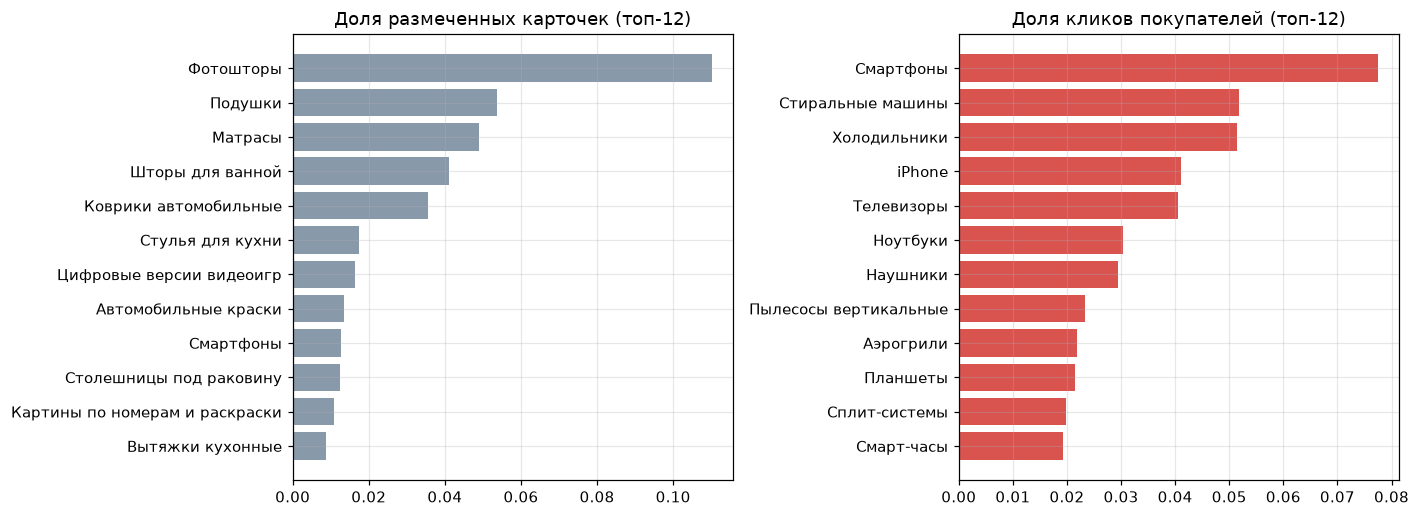

топ-10 категорий по трафику: 38.9% кликов, 12,310 размеченных карточек
топ-30 категорий по трафику: 59.8% кликов, 23,297 размеченных карточек
топ-100 категорий по трафику: 82.6% кликов, 43,652 размеченных карточек
доля трафика у категорий, присутствующих в разметке: 99.6%


In [5]:
by_cards = cards.group_by("category_id").len().rename({"len": "cards"})
c = (cats.join(by_cards, left_on="id", right_on="category_id", how="left").fill_null(0)
     .with_columns((pl.col("cards") / pl.col("cards").sum()).alias("cards_share")))
top_cards = c.sort("cards", descending=True).head(12)
top_traffic = c.sort("clicks", descending=True).head(12)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].barh(top_cards["name"].to_list()[::-1], top_cards["cards_share"].to_list()[::-1], color="#8899aa")
ax[0].set_title("Доля размеченных карточек (топ-12)")
ax[1].barh(top_traffic["name"].to_list()[::-1], top_traffic["traffic_share"].to_list()[::-1], color="#d9534f")
ax[1].set_title("Доля кликов покупателей (топ-12)")
plt.tight_layout(); plt.savefig(FIG / "categories_cards_vs_traffic.png"); plt.show()

ranked = c.sort("clicks", descending=True).with_columns(pl.col("traffic_share").cum_sum().alias("cum"))
for n in (10, 30, 100):
    h = ranked.head(n)
    print(f"топ-{n} категорий по трафику: {h['cum'][-1]:.1%} кликов, {h['cards'].sum():,} размеченных карточек")
print("доля трафика у категорий, присутствующих в разметке:", f"{c.filter(pl.col('cards') > 0)['traffic_share'].sum():.1%}")

**Вывод.** Распределения почти не пересекаются:
- по числу карточек лидируют шторы, подушки и матрасы от крупных продавцов маркетплейса;
- трафик сосредоточен в электронике и технике: смартфоны, стиральные машины, холодильники, телевизоры, ноутбуки.

Если оптимизировать метрику по числу карточек, мы будем оптимизировать шторы. Поэтому главная метрика взвешивается по трафику категорий, а оценочная выборка `test_core` состоит из топ-30 категорий по кликам.

## 4. Продавцы и шаблонные описания

In [6]:
sellers = cards.group_by("seller").len().sort("len", descending=True)
print(f"продавцов: {sellers.height:,} | доля 1P «М.Видео»: {cards.filter(pl.col('seller') == 'М.Видео').height / cards.height:.1%} | "
      f"доля топ-10 продавцов: {sellers.head(10)['len'].sum() / cards.height:.1%}")
# ИП — физические лица: имена в отчёте не показываем
print(sellers.head(8).with_columns(pl.when(pl.col("seller").str.starts_with("ИП "))
                                   .then(pl.lit("ИП (имя скрыто)")).otherwise(pl.col("seller")).alias("seller")))
dup = cards.select(pl.col("description").str.slice(0, 120).n_unique()).item()
print(f"уникальных начал описаний (120 символов): {dup:,} из {cards.height:,}, "
      f"то есть {1 - dup / cards.height:.0%} карточек повторяют начало другой карточки")

продавцов: 1,179 | доля 1P «М.Видео»: 23.3% | доля топ-10 продавцов: 66.1%
shape: (8, 2)
┌──────────────────────┬───────┐
│ seller               ┆ len   │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ М.Видео              ┆ 56342 │
│ ООО "ВЕРТЕКС"        ┆ 48346 │
│ ООО "ПК МЕБЕЛЬРУС"   ┆ 9569  │
│ ИП (имя скрыто)      ┆ 9256  │
│ ООО "Офисмаг"        ┆ 8855  │
│ ООО "АВТОТРЕНД"      ┆ 8554  │
│ ООО "ПРОЕКТ23"       ┆ 6031  │
│ ООО "Холодильник.Ру" ┆ 4699  │
└──────────────────────┴───────┘


уникальных начал описаний (120 символов): 127,834 из 241,355, то есть 47% карточек повторяют начало другой карточки

**Вывод.**
- Две трети карточек дают 10 продавцов.
- Описания одного продавца пишутся по шаблону: почти половина карточек повторяет начало описания другой карточки.
- При случайном разбиении шаблон продавца попадёт и в train, и в test, и метрика окажется завышенной. Поэтому разбиение групповое (раздел 7).

## 5. Характеристики: типы и подтверждаемость текстом

Тип характеристики определяется по её значениям в train:
- `bool` — да/нет;
- `num` — число с единицей;
- `enum` — до 300 вариантов;
- `text` — всё остальное (цвет, серия, модель).

Служебные поля исключены: они не описывают товар.

In [7]:
print("служебные (исключены):", ", ".join(sorted(SERVICE_ATTRIBUTES)))
print(f"схема: {schema.height:,} пар «категория × характеристика» в {schema['category_id'].n_unique():,} категориях, "
      f"медиана {schema.group_by('category_id').len()['len'].median():.0f} характеристик на категорию")
schema.group_by("kind").agg(pl.len().alias("характеристик в схемах")).sort("kind")

служебные (исключены): Вид выпуска товара, Внешний вид, Гарантия предоставляется, Подборки, Потратить бонусы, Признак 18+, Продавец, Состояние
схема: 21,800 пар «категория × характеристика» в 1,093 категориях, медиана 15 характеристик на категорию


kind,характеристик в схемах
str,u32
"""bool""",5932
"""enum""",6055
"""num""",5422
"""text""",4391


**Подтверждаемость.** Ключевой вопрос кейса: какую часть эталона вообще можно найти в тексте карточки.

Значение считается подтверждаемым, если его нормализованная форма встречается в названии или описании:
- для `bool = Да` — упоминается название характеристики;
- `bool = Нет` подтвердить текстом нельзя.

Считаем на стратифицированной выборке val.

In [8]:
val = M.eval_sample(cards, cats, "val", top_k=None, per_category=40, per_group=10)
sup = M.supported_flags(val, gold, schema)
s = (sup.join(gold.select("sku_id", "attribute", "value"), on=["sku_id", "attribute"])
       .join(val.select("sku_id", "category_id"), on="sku_id")
       .join(schema.select("category_id", "attribute", "kind"), on=["category_id", "attribute"]))
print(f"выборка: {val.height:,} карточек, {s.height:,} эталонных пар схемы; подтверждается текстом: {s['supported'].mean():.1%}")
s.group_by("kind").agg(pl.len().alias("пар"), pl.col("supported").mean().alias("подтверждается")).sort("kind")

выборка: 7,087 карточек, 104,643 эталонных пар схемы; подтверждается текстом: 22.6%


kind,пар,подтверждается
str,u32,f64
"""bool""",32476,0.052162
"""enum""",28354,0.138781
"""num""",25164,0.353998
"""text""",18649,0.490482


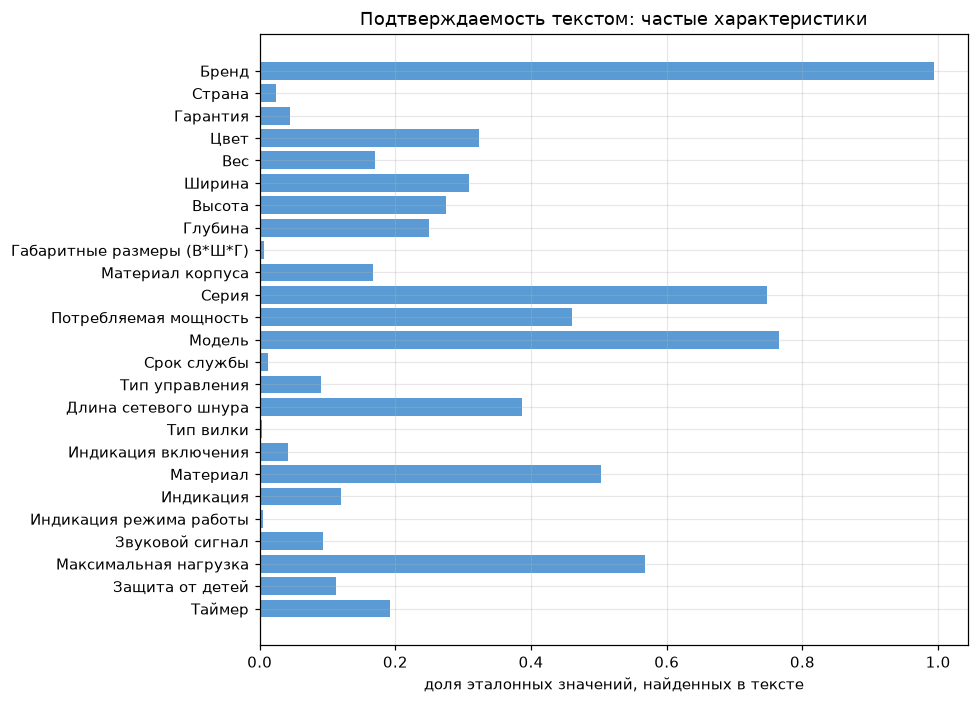

In [9]:
top_attr = (s.group_by("attribute").agg(pl.len().alias("n"), pl.col("supported").mean().alias("supported"))
            .filter(pl.col("n") >= 150).sort("n", descending=True).head(25))
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top_attr["attribute"].to_list()[::-1], top_attr["supported"].to_list()[::-1], color="#5b9bd5")
ax.set_xlabel("доля эталонных значений, найденных в тексте"); ax.set_title("Подтверждаемость текстом: частые характеристики")
plt.tight_layout(); plt.savefig(FIG / "supported_by_attribute.png"); plt.show()

**Вывод.**
- Характеристики «из паспорта товара» почти никогда не встречаются в тексте карточки: страна, гарантия, срок службы, большинство булевых «Нет».
- Бренд, модель, серия, вид принта и размеры в названии подтверждаются хорошо.

Отсюда два следствия для решения:
1. Метрика должна отделять исправимые пропуски (значение есть в тексте) от принципиально недоступных. Поэтому кроме `recall` считаем `recall_supported`.
2. Чтобы заполнить больше полей, нужен второй источник — тот же товар в каталоге у другого продавца. Такие значения помечаются происхождением и получают статус «на проверку».

## 6. Что пишут покупатели в поиске

Доля кликов, в запросе которых встречается характеристика того или иного типа. Это прямой сигнал, какие поля влияют на находимость товара.

In [10]:
PATTERNS = {
    "бренд": None,
    "модель/код (буквы+цифры)": r"\b[a-zа-я]*\d+[a-zа-я]+\d*\b|\b[a-z]+\d{2,}\b",
    "память/объём ГБ-ТБ": r"\d+\s*(гб|gb|тб|tb)\b|\d+\s*/\s*\d+",
    "цвет": r"(черн|бел|сер|серебр|золот|син|голуб|зелен|красн|розов|фиолет|желт|оранж|коричн|бежев)(ый|ий|ой|ая|ое|ые|ого)\b|\b(black|white|silver|gold|blue|pink|green)\b",
    "диагональ/дюймы": r"\d+([.,]\d+)?\s*(дюйм|\"|inch)|\b(32|40|43|50|55|65|75|85)\b",
    "тип установки": r"встраив|напольн|настольн|настенн|отдельностоящ",
    "подключение": r"беспровод|bluetooth|блютуз|wi-?fi|проводн",
    "мощность": r"\d+\s*(вт|w|квт|kw)\b",
    "объём, л": r"\d+([.,]\d+)?\s*(л|литр)",
}
clicks = (qc.group_by("toValidUTF8(query_text)", "toValidUTF8(sku_brand_name)").len()
          .rename({"toValidUTF8(query_text)": "query", "toValidUTF8(sku_brand_name)": "brand"}).collect()
          .with_columns(pl.col("query").str.to_lowercase().alias("ql"), pl.col("brand").str.to_lowercase().alias("bl")))
total = clicks["len"].sum()
rows = []
for name, pattern in PATTERNS.items():
    if pattern is None:
        mask = (pl.col("bl") != "") & pl.col("ql").str.contains(pl.col("bl"), literal=True)
    else:
        mask = pl.col("ql").str.contains(pattern)
    rows.append((name, clicks.filter(mask)["len"].sum() / total))
pl.DataFrame(rows, schema=["характеристика в запросе", "доля кликов"], orient="row").sort("доля кликов", descending=True)

характеристика в запросе,доля кликов
str,f64
"""бренд""",0.194804
"""модель/код (буквы+цифры)""",0.081083
"""тип установки""",0.040816
"""диагональ/дюймы""",0.026363
"""подключение""",0.022268
"""память/объём ГБ-ТБ""",0.01085
"""цвет""",0.008332
"""объём, л""",0.005485
"""мощность""",0.003273


**Вывод.** Чаще всего покупатели указывают в запросе:
- бренд — 19,5% кликов;
- модель или артикул — 8,1%;
- тип установки (встраиваемый, напольный);
- диагональ;
- тип подключения.

Эти поля в первую очередь должны быть заполнены точно: ошибка в них прячет товар из выдачи. Поэтому бренд и ключевые числовые характеристики отнесены в контракте к недопустимым ошибкам.

## 7. Разбиение и утечки

Разбиение групповое:
- группа 3P-карточки — продавец;
- группа 1P-карточки «М.Видео» — бренд.

Группа попадает в train / val / test по `md5(group) mod 100`. Справочники и схема строятся только по train-группам каталога.

In [11]:
sp = cards.group_by("split").agg(pl.len().alias("карточек"), pl.col("group").n_unique().alias("групп"),
                                 (pl.col("seller") == "М.Видео").mean().alias("доля 1P")).sort("split")
cov = (cards.filter(pl.col("split") == "test").select("category_id").unique()
       .join(cats.select(pl.col("id").alias("category_id"), "traffic_share"), on="category_id"))["traffic_share"].sum()
print(sp); print(f"категории test покрывают {cov:.1%} трафика")
core = M.eval_sample(cards, cats, "test")
print(f"test_core: {core.height:,} карточек в {core['category_id'].n_unique()} категориях "
      f"(топ-30 по трафику, не больше 60 на категорию и 20 на продавца)")

shape: (3, 4)
┌───────┬──────────┬───────┬──────────┐
│ split ┆ карточек ┆ групп ┆ доля 1P  │
│ ---   ┆ ---      ┆ ---   ┆ ---      │
│ str   ┆ u32      ┆ u32   ┆ f64      │
╞═══════╪══════════╪═══════╪══════════╡
│ test  ┆ 34173    ┆ 563   ┆ 0.274503 │
│ train ┆ 189499   ┆ 2029  ┆ 0.232114 │
│ val   ┆ 17683    ┆ 298   ┆ 0.169421 │
└───────┴──────────┴───────┴──────────┘
категории test покрывают 95.9% трафика
test_core: 1,398 карточек в 30 категориях (топ-30 по трафику, не больше 60 на категорию и 20 на продавца)


## Итоги EDA

1. **Размеченный набор.** 241 тыс. карточек с текстом и эталоном, медиана 18 характеристик на карточку, 9,2 тыс. разных названий характеристик в 2,6 тыс. категорий. Схема категорий выводится из данных: 1 093 категории с не менее чем 20 train-карточками, медиана 15 обязательных характеристик.
2. **Трафик важнее числа карточек.** Топ-30 категорий по кликам — это 60% трафика и всего 10% размеченных карточек. Основная метрика взвешивается по трафику, `test_core` берётся из топ-30 категорий.
3. **Текст подтверждает только около четверти эталона.** 22,6% эталонных пар находятся в тексте: `bool` 5%, `enum` 14%, `num` 35%, `text` 49%. Остальное — паспортные данные, которых в карточке нет. Поэтому:
   - меряем `recall` и `recall_supported` отдельно;
   - для «паспортных» полей нужен второй источник — аналоги в каталоге со статусом «на проверку».
4. **Шаблоны продавцов создают риск утечки.** 47% карточек повторяют начало чужого описания. Поэтому разбиение групповое: по продавцу, для 1P — по бренду. Справочники строятся только по train.
5. **Описания грязные.** В половине описаний есть HTML, в трети — буллеты «• Ключ: значение». У 26% названий модель пустая (« -» в конце). Очистка HTML и разбор пар «ключ: значение» входят в baseline.